# 横z・縦xで数字1を作る

今回は文字の横方向をz、縦方向をxへ対応させ、目標から各Thread係数を設計し直します。既存の画像の表示だけを転置する処理ではありません。x–zとz–xは同じy=0の物理面で、進行方向はzのままです。

ランク100・15モード・同じThread配置・開口・伝搬範囲を使い、理論伝搬と直接法/提案法の比較を別の結果フォルダへ保存します。中心半径は50 µm。xとzの物理範囲は維持し、その範囲で文字の縦横を入れ替えるため、物理的な剛体90度回転ではありません。詳細は `LSH数字1_zx方向比較.md`。


In [1]:
import importlib
import json
from dataclasses import replace
from pathlib import Path
import lsh_digit1_theory as theory
import lsh_digit1_proposed as proposed
theory = importlib.reload(theory)
proposed = importlib.reload(proposed)

reference_dir = Path('lsh_digit1_proposed_rank100_shiftaware_v2')
if (reference_dir / 'summary.json').is_file():
    old = json.loads((reference_dir / 'summary.json').read_text(encoding='utf-8'))
    if (old.get('study') != 'digit1_direct_vs_projected_shared_core'
            or old.get('mode_spacing_factor', 1) != 1):
        raise ValueError('標準15モードの比較結果を指定してください。')
    values = dict(old['config'])
    values['sensor_z_m'] = tuple(values['sensor_z_m'])
    config = theory.Digit1Config(**values)
else:
    config = theory.Digit1Config()
config = replace(config, digit_axes='zx')
RANK = 100
SEED = 42
library_path = Path(f'lsh_digit1_library_rank{RANK}_shiftaware.npz')
theory_dir = Path('lsh_digit1_theory_zx_outputs_v1')
proposed_dir = Path(f'lsh_digit1_proposed_zx_outputs_rank{RANK}_v1')
print('表示軸：横z、縦x。計算配列：[z,x]。')
print('z範囲[mm]:', config.digit_z_start_m*1000, config.digit_z_end_m*1000)
print('x範囲[mm]:', -config.digit_width_m*500, config.digit_width_m*500)
print('モード数:', theory.mode_design(config).count, 'ランク:', RANK)
print('圧縮辞書:', library_path.resolve())


表示軸：横z、縦x。計算配列：[z,x]。
z範囲[mm]: 75.0 425.0
x範囲[mm]: -0.6 0.6
モード数: 15 ランク: 100
圧縮辞書: C:\Users\kota-\Github\Project_new\research\lsh_digit1_library_rank100_shiftaware.npz


In [2]:
expected = theory.config_payload(config)
summaries = {}
for kind, folder in (('theory', theory_dir), ('proposed', proposed_dir)):
    summary_file = folder / 'summary.json'
    if summary_file.is_file() and (folder / 'manifest.json').is_file():
        data = json.loads(summary_file.read_text(encoding='utf-8'))
        study = 'theory_only_digit1_single_xz_sheet' if kind == 'theory' else 'digit1_direct_vs_projected_shared_core'
        version = theory.THEORY_SCHEMA_VERSION if kind == 'theory' else proposed.SCHEMA_VERSION
        valid = (data.get('study') == study and data.get('schema_version') == version
                 and theory.config_payload(data.get('config', {})) == expected)
        if kind == 'proposed':
            valid = valid and (data.get('rank') == RANK and data.get('seed') == SEED
                and data.get('basis_strategy') == 'shift_aware'
                and data.get('mode_spacing_factor', 1) == 1
                and data.get('library_path') == str(library_path.resolve()))
        if not valid:
            raise ValueError(f'{folder}: 別条件です。新しい保存先に変更してください。')
        print('同じ条件の結果を読み込み:', folder)
    elif folder.exists() and any(folder.iterdir()):
        raise ValueError(f'{folder}: 途中結果です。保存先をv2などへ変更してください。')
    elif kind == 'theory':
        data = theory.run_digit1(folder, config)
    else:
        data = proposed.run_comparison(folder, config, rank=RANK, seed=SEED,
            library_path=library_path, basis_strategy='shift_aware', run_shift_diagnostics=True)
    summaries[kind] = data
    print(kind, '保存先:', folder.resolve())


Initial field: thread 4/21
Initial field: thread 5/21
Initial field: thread 6/21
Initial field: thread 7/21
Initial field: thread 8/21
Initial field: thread 9/21
Initial field: thread 10/21
Initial field: thread 11/21
Initial field: thread 12/21
Initial field: thread 13/21
Initial field: thread 14/21
Initial field: thread 15/21
Initial field: thread 16/21
Initial field: thread 17/21
Initial field: thread 18/21
Initial field: thread 19/21
Sensor propagation: 1/101, z=0.0 mm
Sensor propagation: 6/101, z=25.0 mm
Sensor propagation: 11/101, z=50.0 mm
Sensor propagation: 16/101, z=75.0 mm
Sensor propagation: 21/101, z=100.0 mm
Sensor propagation: 26/101, z=125.0 mm
Sensor propagation: 31/101, z=150.0 mm
Sensor propagation: 36/101, z=175.0 mm
Sensor propagation: 41/101, z=200.0 mm
Sensor propagation: 46/101, z=225.0 mm
Sensor propagation: 51/101, z=250.0 mm
Sensor propagation: 56/101, z=275.0 mm
Sensor propagation: 61/101, z=300.0 mm
Sensor propagation: 66/101, z=325.0 mm
Sensor propagation:

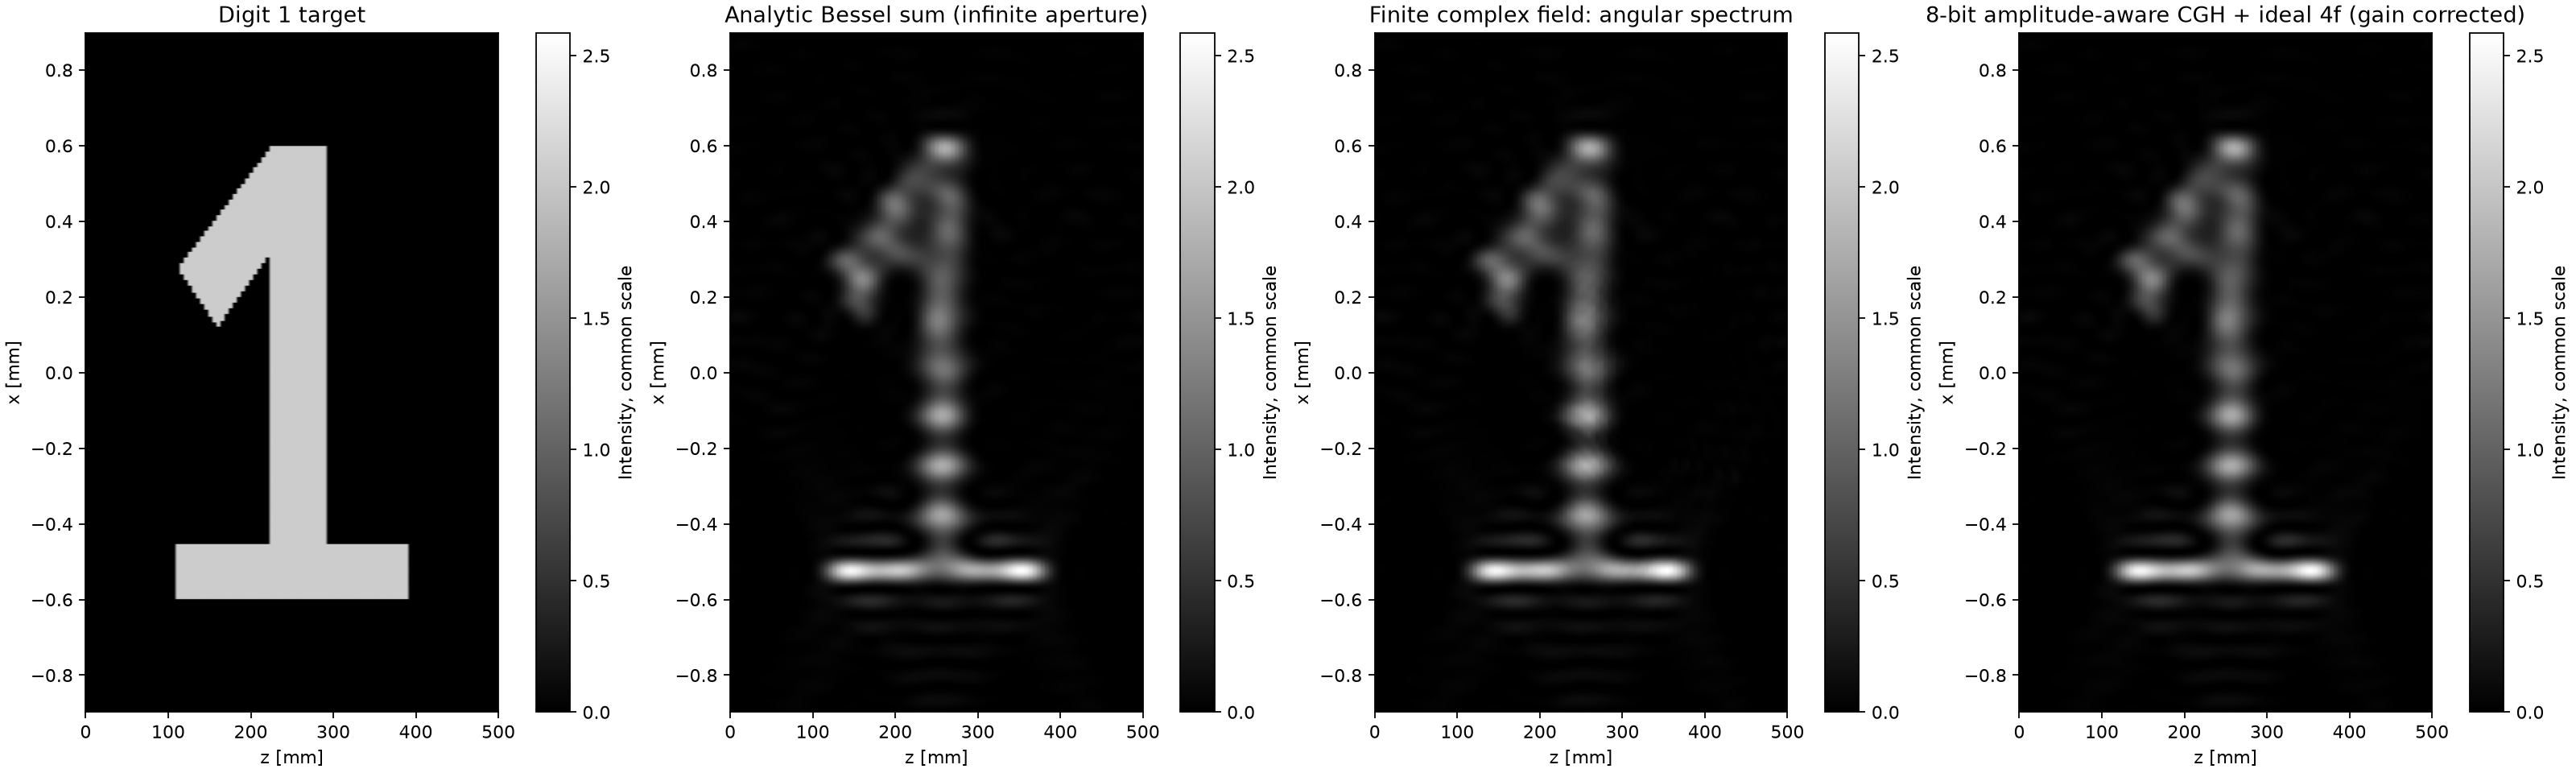

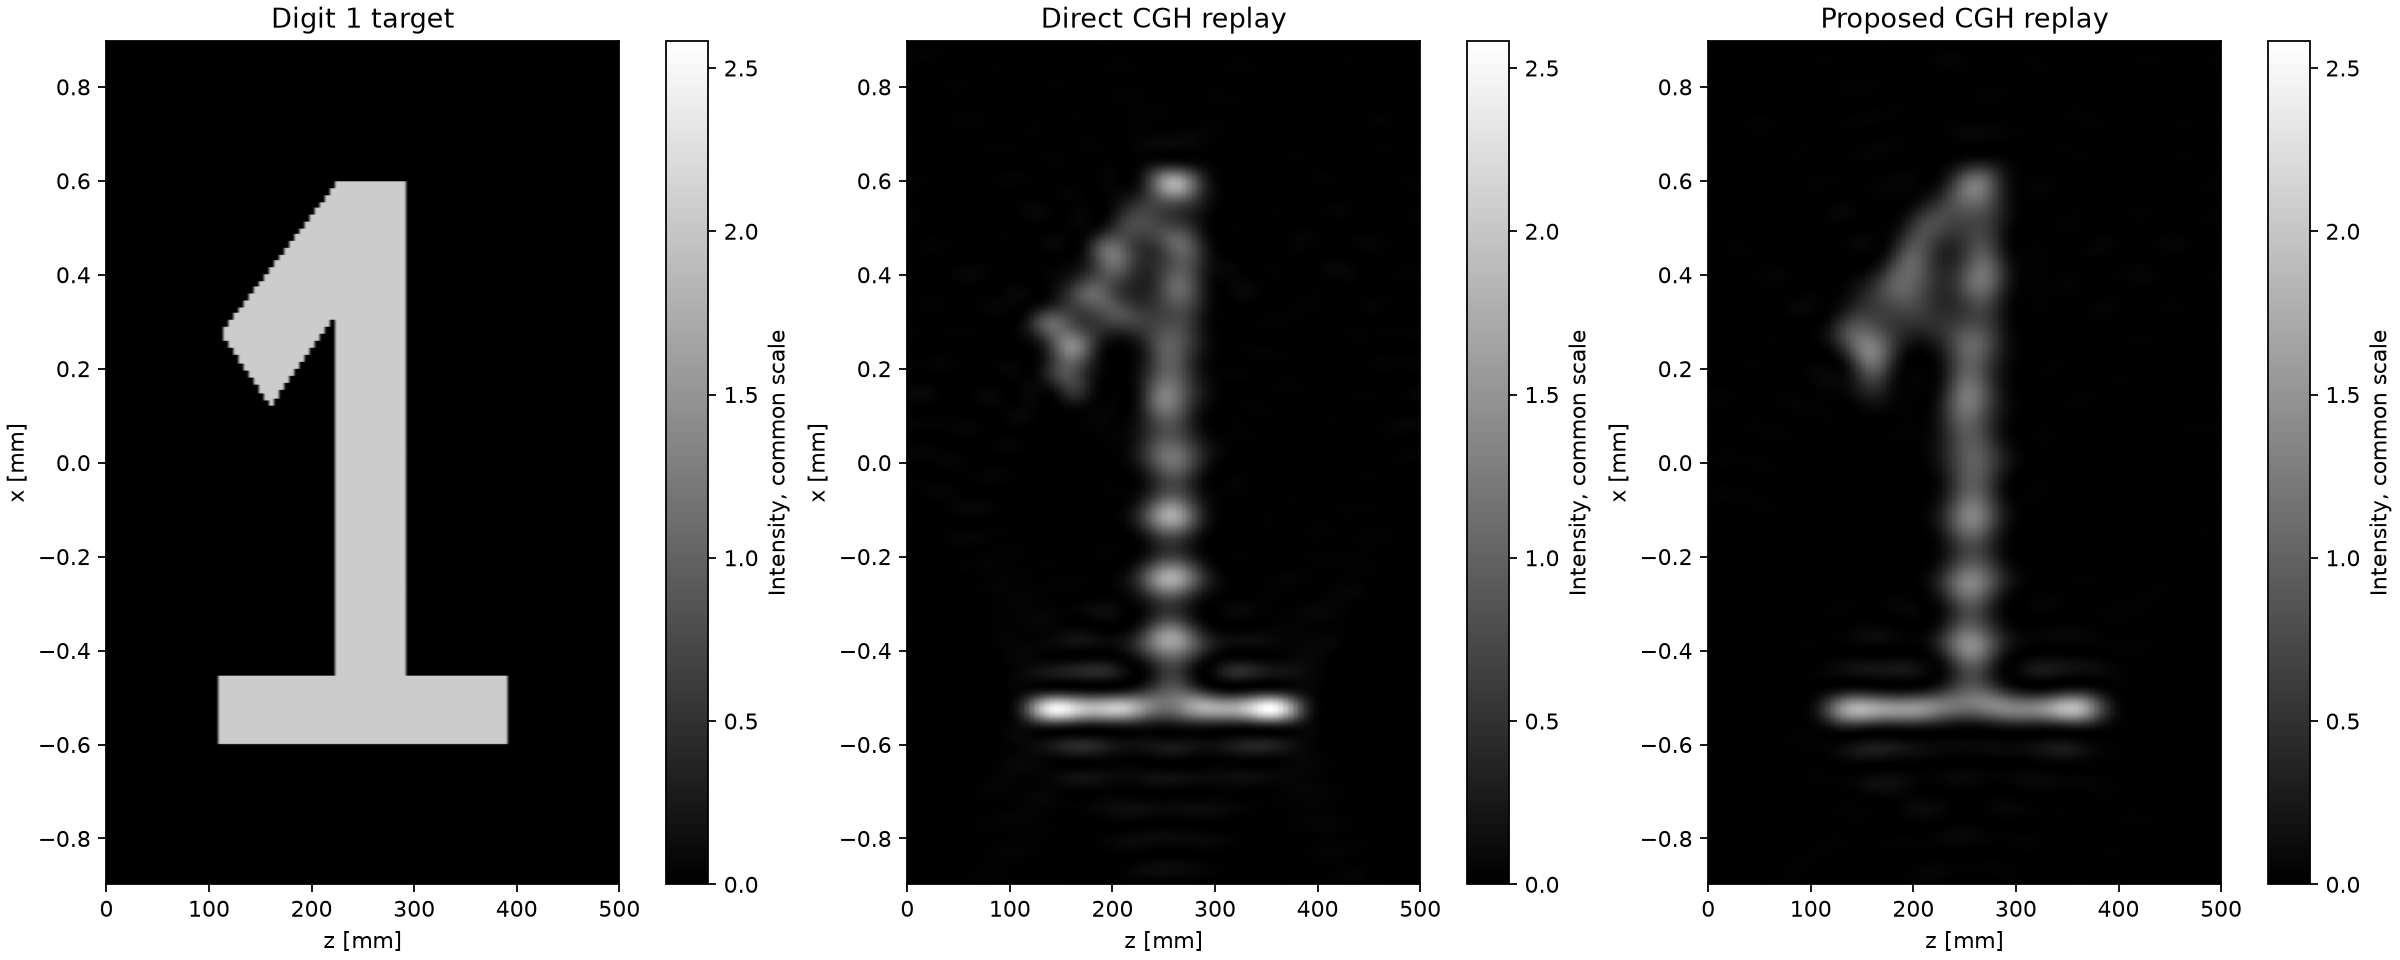

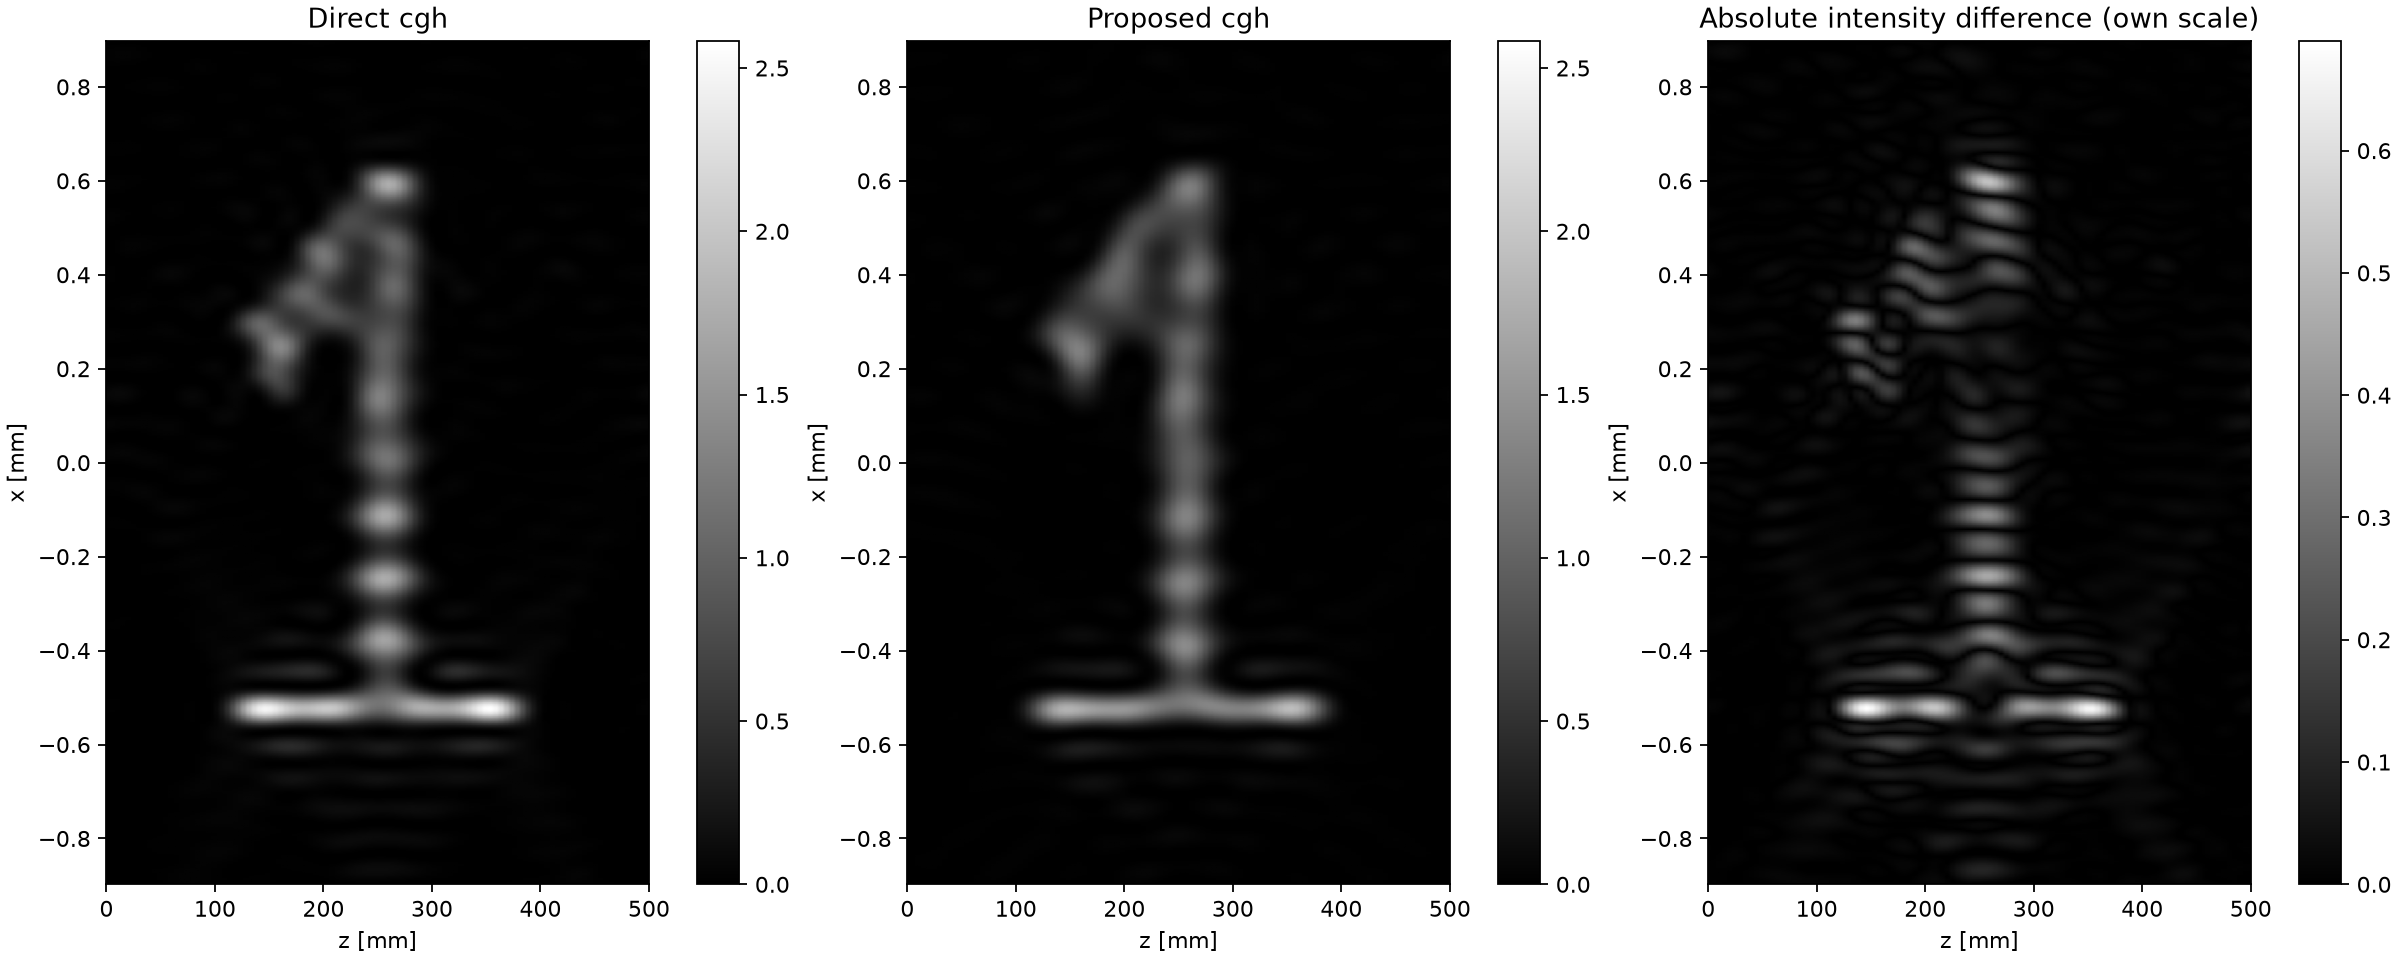

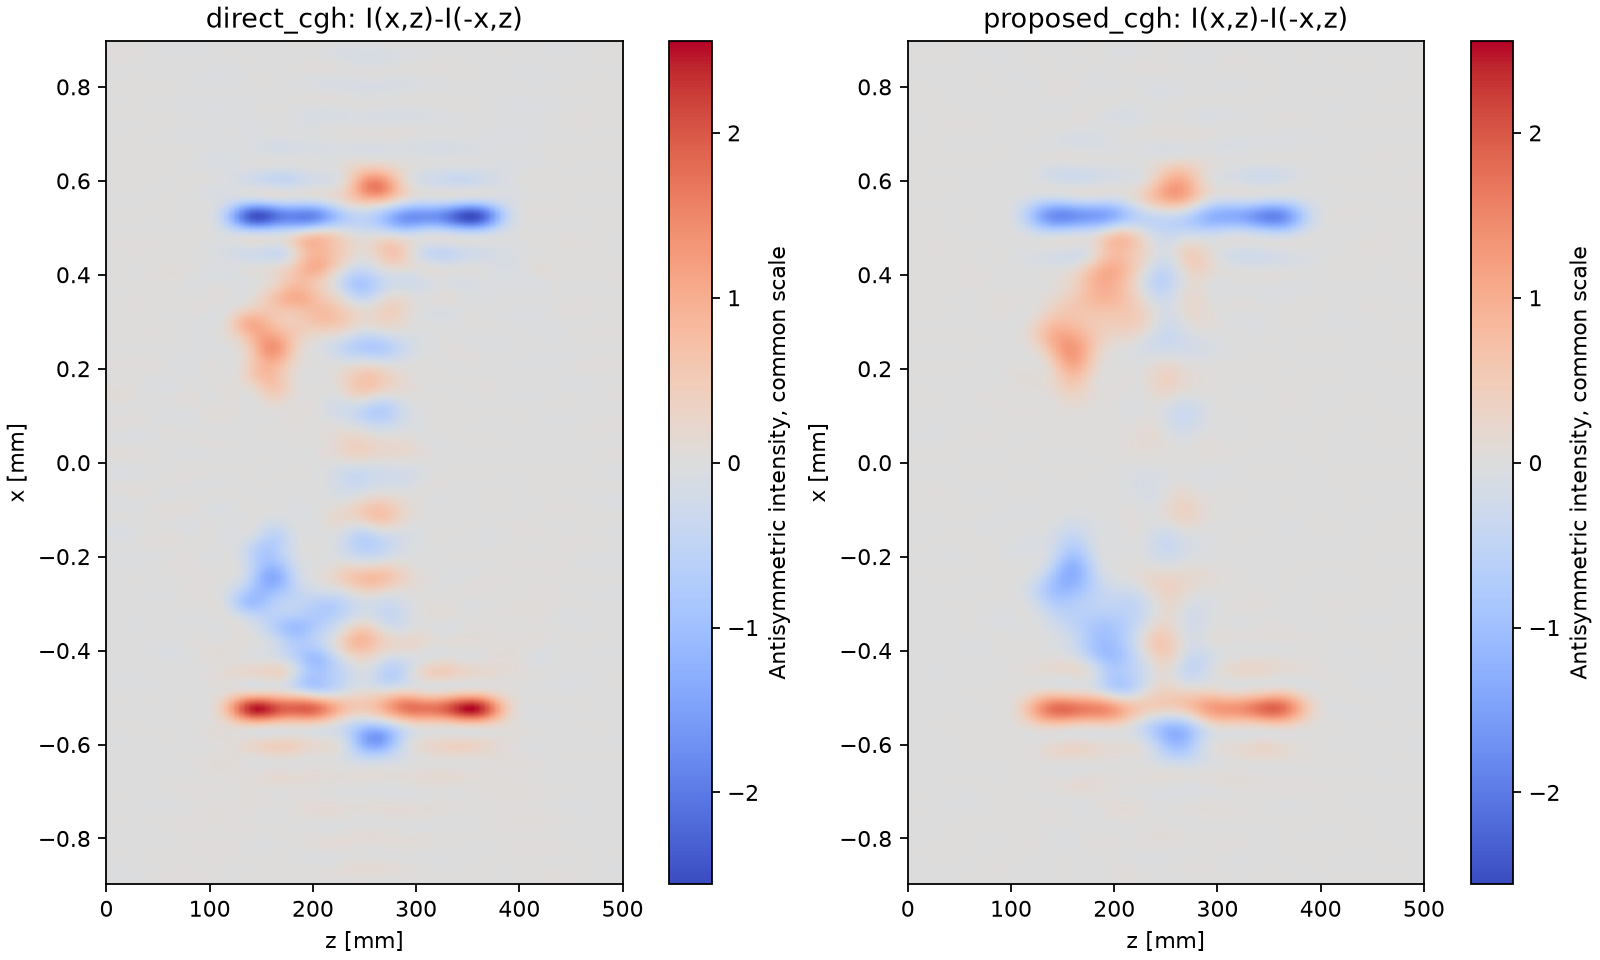

実際の非零Thread数: 16
Bessel項数: 240
提案法/直接法：CGH再生後: {'complex_relative_l2': 0.23570214475432072, 'intensity_relative_l2': 0.2062972534312888, 'ssim': 0.9129357965425828, 'psnr_db': 31.87295684257005, 'snr_db': 13.71013108063157}
直接法/目標: {'intensity_relative_l2': 0.7242369376709115, 'ssim': 0.4948594484405859, 'psnr_db': 10.90140894140331, 'snr_db': 2.8023865796770204}
提案法/目標: {'intensity_relative_l2': 0.7307108685517794, 'ssim': 0.5790741971121555, 'psnr_db': 10.824111020434092, 'snr_db': 2.7250886587078043}
生成時間: {'direct_field_generation': 37.938180700002704, 'proposed_field_generation': {'thread_core_weighting_seconds': 0.0034091999841621146, 'shift_operator_seconds': 0.06500560001586564, 'shifted_core_sum_seconds': 0.003861700024572201, 'spatial_factor_reconstruction_seconds': 0.023370700000668876, 'field_generation_seconds': 0.09589179999602493}, 'cgh_encode_and_ideal4f_replay': {'direct': 1.33475009999529, 'proposed': 1.3457053000020096}, 'all_four_propagation': 68.45030300000508}
CGH

In [3]:
from IPython.display import Image, display
display(Image(filename=str(theory_dir / 'digit1_sheet_comparison.png'), width=1300))
for filename in ('target_direct_proposed.png', 'cgh_sheet_comparison.png', 'asymmetry_comparison.png'):
    display(Image(filename=str(proposed_dir / filename), width=1200))
result = summaries['proposed']
print('実際の非零Thread数:', result['active_thread_count'])
print('Bessel項数:', result['nonzero_bessel_term_count'])
print('提案法/直接法：CGH再生後:', result['metrics']['cgh_sheet_proposed_vs_direct'])
print('直接法/目標:', result['metrics']['direct_cgh_sheet_vs_target'])
print('提案法/目標:', result['metrics']['proposed_cgh_sheet_vs_target'])
print('生成時間:', result['timings_seconds'])
print('CGH:', (proposed_dir / 'proposed_cgh_8bit.png').resolve())
print('センサー断面:', (proposed_dir / 'sensor_xy').resolve())
